# Etapa 4: Random Tree

Entrada: a mesma matriz de features e os mesmos dois splits do notebook 03 (`modeling.prepare`).

A **Random Tree** (classe `RandomTree` do Weka) é uma árvore de decisão com uma única mudança: em cada nó, ela sorteia K atributos e procura o melhor corte só entre eles, em vez de olhar todos. Ela não usa poda nem limite de profundidade. O K padrão do Weka é `log2(atributos) + 1`.

A etapa responde a três perguntas:

1. **O sorteio de atributos ajuda ou atrapalha uma árvore única?** A comparação é feita cenário a cenário com a árvore de decisão do notebook 03, com o mesmo protocolo de busca e de validação.
2. **Qual K funciona melhor?**
3. **Quanto o resultado depende da sorte?** A mesma configuração é treinada com 50 sementes.

O código fica em `src/random_tree.py`. As funções de busca, avaliação e erro são as de `src/modeling.py`, as mesmas da árvore de decisão.

## 0. Configuração

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

%load_ext autoreload
%autoreload 2

import pandas as pd
from IPython.display import display

from src import modeling, plots, random_tree as rt
from src.config import FINAL_CSV

plots.set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

final = pd.read_csv(FINAL_CSV)
dados = modeling.prepare(final)
print("X:", dados.X.shape, "| classes:", dados.y.nunique())

X: (27476, 17) | classes: 4


## 1. A Random Tree no scikit-learn

O scikit-learn não tem uma classe `RandomTree`, mas o `DecisionTreeClassifier` faz o mesmo sorteio quando recebe `max_features=K`: a cada nó, ele escolhe K atributos ao acaso e só testa cortes neles. Com `max_features=None` (o padrão), a árvore testa todos os atributos e vira a árvore de decisão do notebook 03.

| | Weka `RandomTree` | scikit-learn |
|---|---|---|
| atributos por nó | `-K`, padrão `log2(n) + 1` | `max_features=K` |
| critério | ganho de informação | `criterion="entropy"` |
| poda | nenhuma | `ccp_alpha=0` (padrão) |
| profundidade | sem limite | `max_depth=None` (padrão) |
| folha mínima | 1 instância | `min_samples_leaf=1` (padrão) |

O K do Weka para cada conjunto de features:

In [2]:
pd.DataFrame({"atributos": {f: len(c) for f, c in rt.FEATURE_SETS.items()},
              "K padrão do Weka": {f: rt.weka_k(len(c)) for f, c in rt.FEATURE_SETS.items()}})

,atributos,K padrão do Weka
descritores,5,3
descritores + SMILES,17,5
só SMILES,12,4


## 2. A configuração padrão do Weka

Primeiro, a Random Tree exatamente como o Weka a entrega, sem nenhum ajuste, nos 6 cenários (3 conjuntos de features × 2 splits).

In [3]:
padrao, _ = rt.default_all(dados)
padrao

,features,split,K,acurácia teste,F1 macro teste,folhas,profundidade
0,descritores,aleatória,3,0.800,0.798,4304,25
1,descritores,agrupada,3,0.757,0.755,4366,27
2,descritores + SMILES,aleatória,5,0.903,0.903,2598,22
3,descritores + SMILES,agrupada,5,0.882,0.882,2559,23
4,só SMILES,aleatória,4,0.877,0.874,3924,25
5,só SMILES,agrupada,4,0.874,0.872,3871,25


Sem ajuste, a Random Tree fica abaixo da árvore de decisão do notebook 03 nos 6 cenários. No cenário escolhido ela acerta 0,882, contra 0,897 da árvore. As árvores também saem maiores: 2.559 folhas contra 1.854. Faz sentido: com só 5 dos 17 atributos disponíveis em cada nó, muitos cortes usam um atributo pior do que o melhor possível. A árvore então precisa de mais divisões para separar as mesmas classes.

## 3. Busca de hiperparâmetros

O mesmo protocolo do notebook 03: `GridSearchCV` com 5 partes, e validação cruzada agrupada quando o split externo é agrupado. O grid tem 54 combinações:

- `criterion`: gini, entropy;
- `max_features`: 0,25, 0,5, 0,75 do total de atributos (K = 4, 8 e 12 com 17 atributos; K = 1, 2 e 3 com os 5 descritores);
- `max_depth`: 12, 16, sem limite;
- `min_samples_leaf`: 1, 5, 20.

`max_features` aparece como fração porque o conjunto "descritores" tem só 5 colunas: um K fixo como 8 não existiria nele.

In [4]:
comparacao, modelos = modeling.tune_all(dados, rt.PARAM_GRID, rt.estimator(dados.seed))
comparacao

,features,split,acurácia CV,acurácia teste,F1 macro teste,folhas,profundidade
0,descritores,aleatória,0.788,0.804,0.802,4503,26
1,descritores,agrupada,0.743,0.755,0.753,3456,16
2,descritores + SMILES,aleatória,0.892,0.907,0.906,2203,25
3,descritores + SMILES,agrupada,0.877,0.886,0.885,1685,16
4,só SMILES,aleatória,0.882,0.895,0.893,2846,26
5,só SMILES,agrupada,0.862,0.873,0.870,2999,23


In [5]:
modeling.best_params_table(modelos, rt.PARAM_GRID)

,features,split,criterion,max_depth,max_features,min_samples_leaf
0,descritores,aleatória,gini,NaN,0.75,1
1,descritores,agrupada,gini,16.0,0.75,1
2,descritores + SMILES,aleatória,entropy,NaN,0.50,1
3,descritores + SMILES,agrupada,entropy,16.0,0.75,1
4,só SMILES,aleatória,entropy,NaN,0.75,1
5,só SMILES,agrupada,entropy,NaN,0.75,1


A busca puxa a Random Tree de volta na direção da árvore de decisão. Em 5 dos 6 cenários ela escolhe `max_features = 0,75`, a maior fração do grid, ou seja, o menor sorteio possível. Folha mínima de 1 linha em todos, como na árvore. A profundidade máxima de 16 aparece em dois cenários do split agrupado: com o sorteio, a árvore cresce mais (até 27 níveis no padrão do Weka) e o limite corta ramos que só decoravam o treino.

## 4. Random Tree contra a árvore de decisão

A árvore de decisão é ajustada de novo aqui, com o grid do notebook 03, para comparar os dois modelos com os mesmos dados e o mesmo split.

In [6]:
comparacao_dt, modelos_dt = modeling.tune_all(dados)
rt.versus_tree(comparacao, comparacao_dt)

,features,split,acurácia teste RT,folhas RT,acurácia teste DT,folhas DT,diferença (pontos)
0,descritores,aleatória,0.804,4503,0.807,3330,-0.3
1,descritores,agrupada,0.755,3456,0.771,1124,-1.6
2,descritores + SMILES,aleatória,0.907,2203,0.907,1849,0.0
3,descritores + SMILES,agrupada,0.886,1685,0.897,1854,-1.1
4,só SMILES,aleatória,0.895,2846,0.892,2818,0.3
5,só SMILES,agrupada,0.873,2999,0.876,2758,-0.3


**O sorteio de atributos não ajuda uma árvore única.** Em 4 dos 6 cenários a Random Tree fica abaixo da árvore de decisão; nos outros dois, empata ou passa por 0,3 ponto. A maior perda acontece no split agrupado, o mais honesto: −1,6 ponto com os descritores e −1,1 ponto com descritores + SMILES.

A razão é simples. Uma árvore única quer o melhor corte em cada nó, e o sorteio às vezes esconde esse corte. O sorteio só vale a pena quando muitas árvores diferentes são combinadas: cada uma erra de um jeito, e a média cancela os erros. Esse é o papel da Random Forest (notebook 05). O notebook 07 repete esta comparação com 10 seeds.

## 5. Quantos atributos sortear

A curva varre K de 1 a 17 no cenário escolhido (descritores + SMILES, split agrupado), com os demais hiperparâmetros fixos nos valores escolhidos pela busca. K = 17 desliga o sorteio: é a árvore de decisão com os mesmos parâmetros.

parâmetros escolhidos: {'criterion': 'entropy', 'max_depth': 16, 'max_features': 0.75, 'min_samples_leaf': 1}


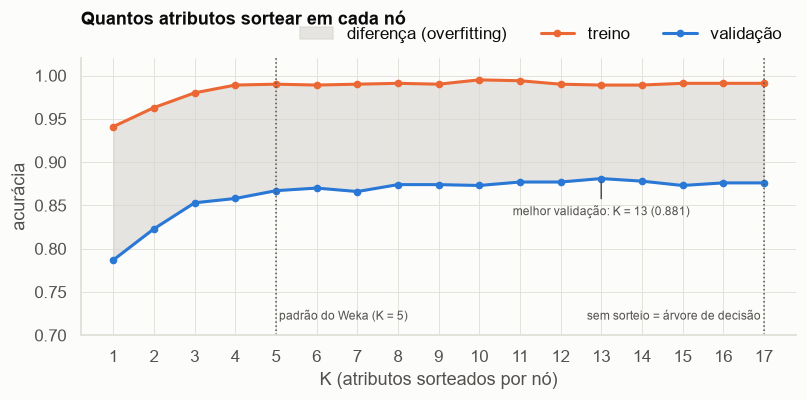

K (atributos sorteados por nó),1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
treino,0.941,0.963,0.980,0.989,0.990,0.989,0.990,0.991,0.990,0.995,0.994,0.990,0.989,0.989,0.991,0.991,0.991
validação,0.787,0.823,0.853,0.858,0.867,0.870,0.866,0.874,0.874,0.873,0.877,0.877,0.881,0.878,0.873,0.876,0.876


In [7]:
random_tree = modelos[modeling.CHOSEN]
params = modeling.chosen_params(random_tree, rt.PARAM_GRID)
print("parâmetros escolhidos:", params)
curva_k = rt.max_features_curve(dados, params)
plots.max_features_curve(curva_k, weka_k=rt.weka_k(len(dados.X.columns)))
curva_k.T

A validação sobe rápido de K = 1 (0,787) a K = 5 (0,867), o padrão do Weka, e depois fica num platô entre 0,866 e 0,881. O melhor ponto, K = 13 (0,881), fica só 0,5 ponto acima de K = 17 (0,876), a árvore sem sorteio. Essa diferença é menor que a variação entre sementes medida na próxima seção. Na prática, qualquer K de 8 para cima dá o mesmo resultado.

Com K pequeno, o treino também cai (0,941 em K = 1): a árvore nem consegue decorar o treino, porque muitos nós só podem cortar por atributos ruins.

## 6. Quanto o resultado depende da semente

A Random Tree muda a cada semente: o sorteio de atributos escolhe outros cortes. Aqui a mesma configuração é treinada com 50 sementes, no mesmo treino, e avaliada no mesmo teste. A árvore de decisão com os mesmos parâmetros (sem sorteio) entra como comparação. Nela, a semente só desempata cortes com o mesmo ganho, então ela deve variar muito pouco.

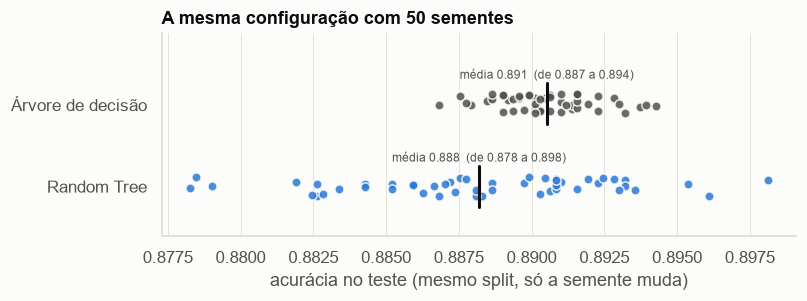

,mean,std,min,max
modelo,,,,
Random Tree,0.8882,0.0045,0.8783,0.8981
Árvore de decisão,0.8905,0.0017,0.8868,0.8943


In [8]:
variancia = rt.seed_variance(dados, params)
plots.seed_variance(variancia)
rt.seed_summary(variancia)

Só trocar a semente, sem mudar dados nem split, move a acurácia da Random Tree de 0,878 a 0,898: **2 pontos de amplitude**, com desvio padrão de 0,45 ponto. A árvore de decisão com os mesmos parâmetros varia de 0,887 a 0,894, com desvio de 0,17 ponto, 2,6 vezes menor.

Na média, a Random Tree perde 0,2 ponto para a árvore (0,888 contra 0,891). Algumas sementes passam da árvore, mas ninguém sabe de antemão qual semente vai dar sorte. Essa instabilidade é o que a Random Forest aproveita: 300 Random Trees diferentes, com erros diferentes, se compensam na média.

## 7. Avaliação no conjunto de teste

A Random Tree escolhida pela busca no cenário principal, com as mesmas análises da árvore de decisão.

In [9]:
relatorio, matriz = modeling.evaluation(random_tree, dados)
relatorio

,precisão,revocação,F1,linhas
EGFR,0.882,0.877,0.879,1612.000
BACE1,0.898,0.912,0.905,1463.000
DRD2,0.903,0.891,0.897,1307.000
HDAC1,0.856,0.859,0.858,1114.000
accuracy,0.886,0.886,0.886,0.886
macro avg,0.885,0.885,0.885,5496.000


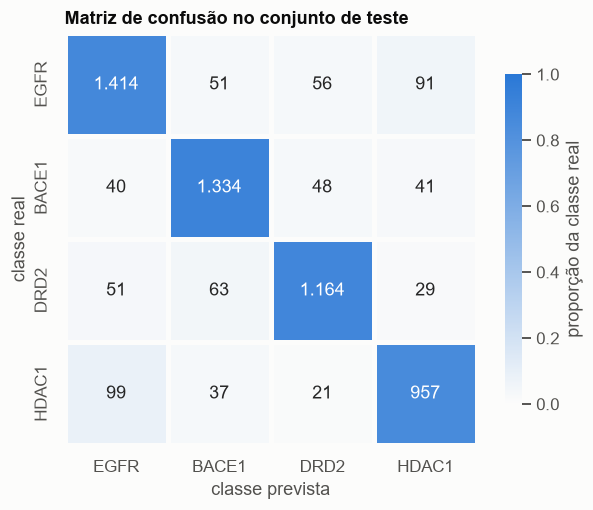

In [10]:
plots.confusion_matrix(matriz)

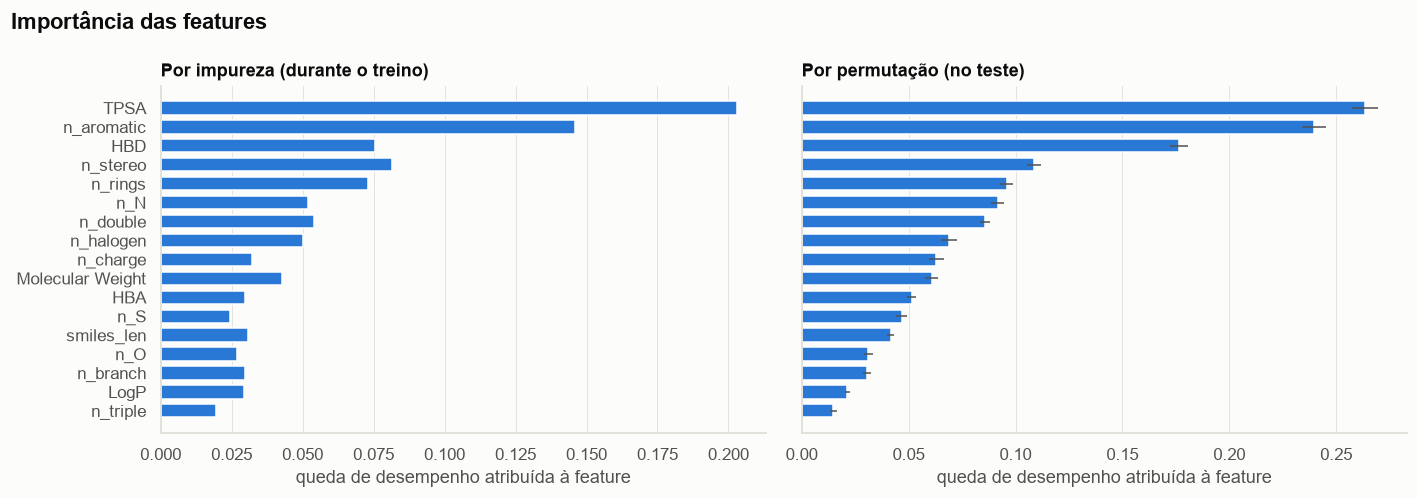

In [11]:
plots.feature_importances(modeling.importances(random_tree, dados))

In [12]:
modeling.confidence_table(random_tree, dados)

,previsões,% do teste,acurácia
faixa,,,
até 50%,15,0.3,0.467
50-70%,121,2.2,0.496
70-90%,177,3.2,0.763
90-100%,131,2.4,0.916
100% (folha pura),5052,91.9,0.900


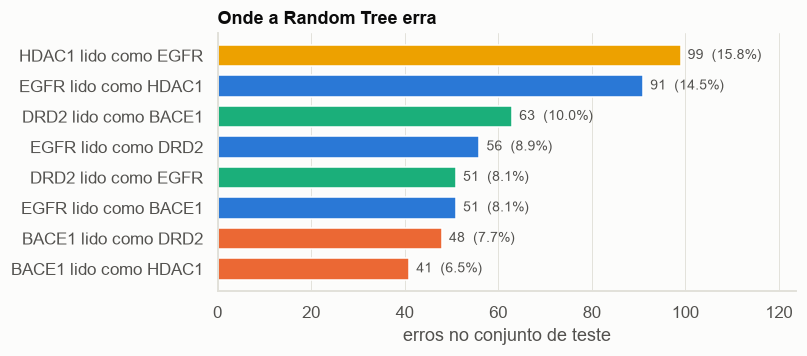

,real,prevista,erros,% dos erros,% da classe real
0,HDAC1,EGFR,99,15.8,8.9
1,EGFR,HDAC1,91,14.5,5.6
2,DRD2,BACE1,63,10.0,4.8
3,EGFR,DRD2,56,8.9,3.5
4,DRD2,EGFR,51,8.1,3.9
5,EGFR,BACE1,51,8.1,3.2


In [13]:
erros = modeling.error_overview(random_tree, dados)
plots.error_pairs(erros, title="Onde a Random Tree erra")
erros.head(6)

Acurácia de 0,886 e F1 macro de 0,885 no teste, cerca de 1 ponto abaixo da árvore de decisão (0,897). O padrão por classe é o mesmo da árvore: BACE1 e DRD2 são as mais fáceis (F1 0,905 e 0,897) e HDAC1 a mais difícil (0,858). O par HDAC1 ↔ EGFR continua concentrando os erros: 30,3% deles, nos dois sentidos, contra 28,7% na árvore.

As importâncias também batem com as da árvore: TPSA e `n_aromatic` lideram nas duas medidas, e HBD vem em terceiro na permutação. O sorteio espalha um pouco o crédito, porque cada nó só vê parte dos atributos, mas não muda quem importa.

A confiança mudou pouco. Com `max_depth = 16`, algumas folhas não chegam a ficar puras, então 8% das previsões saem com menos de 100% de confiança. Ainda assim, 91,9% das previsões dizem 100% e erram 10% das vezes. A Random Tree herda da árvore a incapacidade de dizer quando está em dúvida.

## 8. Resumo

| Cenário (descritores + SMILES, split agrupado) | Acurácia no teste |
|---|---|
| Árvore de decisão (notebook 03) | 0,897 |
| Random Tree, padrão do Weka (K = 5) | 0,882 |
| Random Tree ajustada (K = 12, profundidade 16) | 0,886 |

- **O sorteio de atributos não ajuda uma árvore única.** Ajustada, a Random Tree fica abaixo da árvore de decisão ou empata em 5 dos 6 cenários; sem ajuste, fica abaixo nos 6. No split agrupado, a perda vai de 0,3 a 1,6 ponto.
- **A busca reduz o sorteio.** Ela escolhe a maior fração de atributos do grid (0,75) em 5 dos 6 cenários, e a curva de K mostra um platô de K = 8 em diante. A Random Tree melhora quanto mais parecida fica com a árvore de decisão.
- **A Random Tree é instável.** Só a semente muda o resultado em até 2 pontos, com desvio 2,6 vezes maior que o da árvore.
- **O que a Random Tree aprende é o mesmo.** Mesmas features importantes, mesma classe difícil (HDAC1), mesmo par de confusão (HDAC1 ↔ EGFR) e a mesma confiança de 100% em quase tudo.

A Random Tree sozinha não vale a troca: perde acurácia e estabilidade e não ganha nada em legibilidade. O valor dela aparece quando muitas são combinadas, que é o assunto do notebook 05 (Random Forest) e do experimento-ponte no notebook 07.